# Clustering

Clustering requires only unlabeled, numeric data, since distance-based algorithms like K-Means and hierarchical clustering can't interpret text categories or a target label the way a model like Naive Bayes or Decision Trees can. For this reason, columns like Insurance_Type, State, Claim_Status, and Is_Fraud were excluded from the clustering input entirely, even though they're useful elsewhere in the project. What remains is a purely numeric subset of the data: Claim_Amount, Approved_Amount, Patient_Age, Number_of_Claims_Per_Provider_Monthly, Days_Between_Service_and_Claim, Length_of_Stay, Prior_Visits_12m, and Premiums.

Before clustering, every feature was also standardized (scaled to have a mean of 0 and a standard deviation of 1), since features like Claim_Amount and Patient_Age sit on very different numeric scales, and an unscaled distance calculation would let the larger-scale features dominate the result.

/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight


KMeans_Cluster
3    3998
0    3901
1    1331
2     770
Name: count, dtype: int64


/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/u

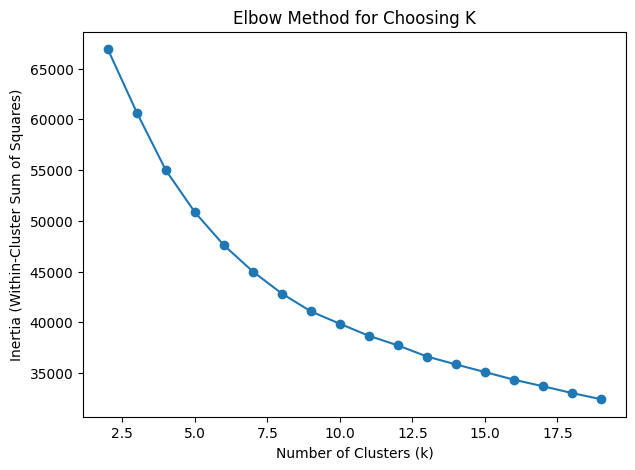

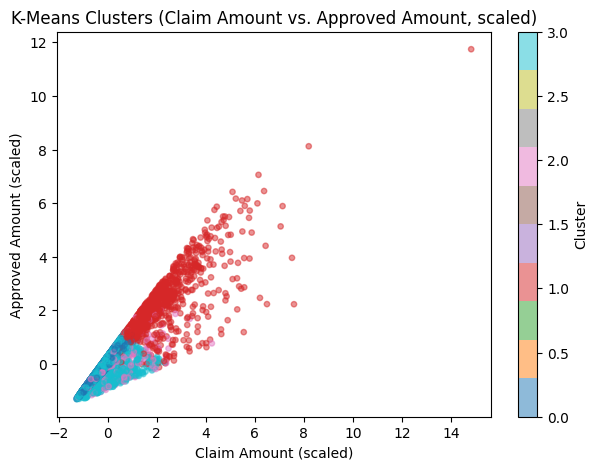

/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarnin

The value of k that maximizes the silhouette score: 2


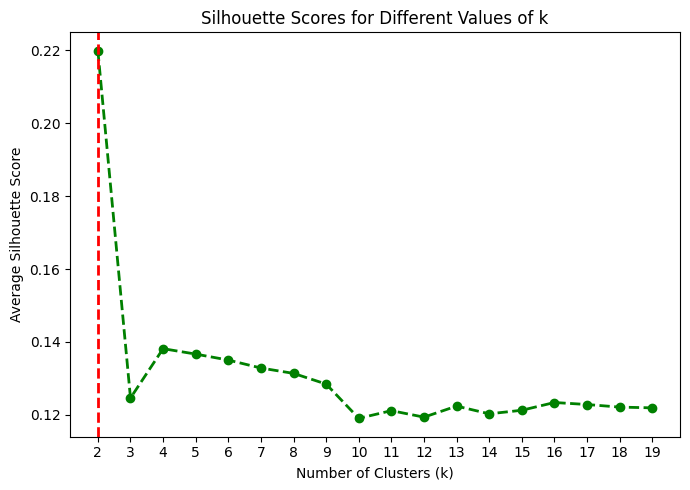

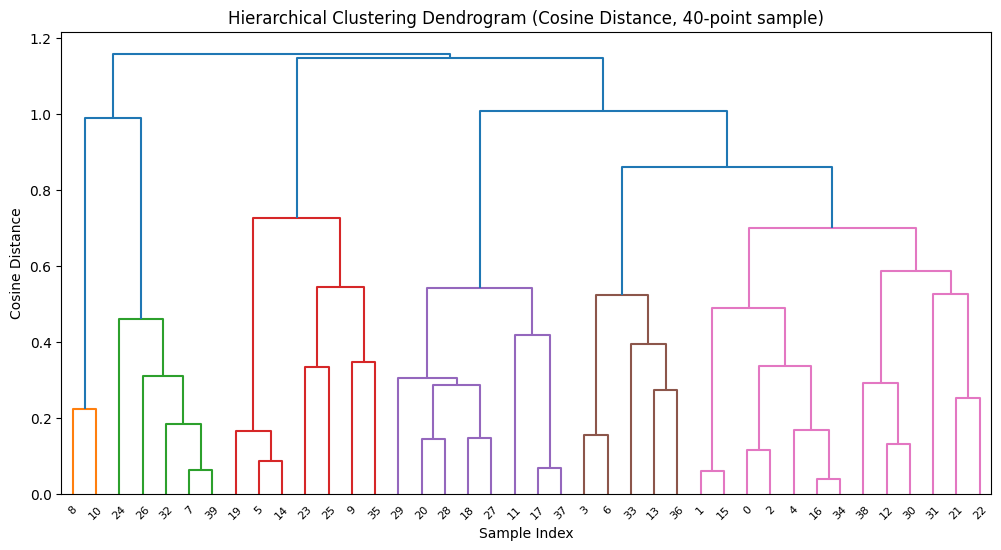

Hierarchical_Cluster
0    4903
3    2277
1    2108
2     712
Name: count, dtype: int64


In [ ]:
import seaborn as sns
import pandas as pd
import scipy
import IPython
import sklearn
import matplotlib.pyplot as plt
import numpy as np
import os
import requests
import plotly.express as px
import plotly.graph_objects as go
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore', message='invalid value encountered in matmul')
warnings.filterwarnings('ignore', message='divide by zero encountered in matmul')

health_data = pd.read_csv('health_data.csv')

num_cols = ['Claim_Amount','Approved_Amount', 'Patient_Age', 'No_of_Claims_Provider',
                       'Service_Claim_days','Length_of_Stay','Prior_Visits_12m', 'Premiums']

cluster_data = health_data[num_cols].dropna()


# Scaling the data so no single feature dominates due to scale differences
scaler = StandardScaler()
scaled_data = scaler.fit_transform(cluster_data)

row_norms = np.linalg.norm(scaled_data, axis=1)
cluster_data = cluster_data[row_norms != 0]

# ---- K-MEANS (Partitional Clustering) ----
kmeans = KMeans(n_clusters=4, random_state=0, n_init=10)
kmeans_labels = kmeans.fit_predict(scaled_data)
cluster_data['KMeans_Cluster'] = kmeans_labels

print(cluster_data['KMeans_Cluster'].value_counts())

# Elbow method
inertias = []
k_range = range(2, 20)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=0, n_init=10)
    km.fit(scaled_data)
    inertias.append(km.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(list(k_range), inertias, marker='o')
plt.title('Elbow Method for Choosing K')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.savefig('kmeans_elbow.png', dpi=300, bbox_inches='tight')
plt.show()

# Visualize the K-Means clusters
plt.figure(figsize=(7, 5))
plt.scatter(scaled_data[:, 0], scaled_data[:, 1], c=kmeans_labels, cmap='tab10', alpha=0.5, s=15)
plt.title('K-Means Clusters (Claim Amount vs. Approved Amount, scaled)')
plt.xlabel('Claim Amount (scaled)')
plt.ylabel('Approved Amount (scaled)')
plt.colorbar(label='Cluster')
plt.savefig('kmeans_clusters.png', dpi=300, bbox_inches='tight')
plt.show()


# Silhouette Method

k_range = range(2, 20)
silhouette_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=0, n_init=10)
    labels = km.fit_predict(scaled_data)
    score = silhouette_score(scaled_data, labels)
    silhouette_scores.append(score)

optimal_k = silhouette_scores.index(max(silhouette_scores)) + 2
print(f"The value of k that maximizes the silhouette score:",optimal_k)

plt.figure(figsize=(7, 5))
plt.plot(k_range, silhouette_scores, marker='o', linestyle='--', color='green', linewidth=2, label='Silhouette Score')
plt.axvline(x=optimal_k, color='red', linestyle='--', linewidth=2, label='Optimal K')
plt.title('Silhouette Scores for Different Values of k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Silhouette Score')
plt.xticks(k_range)
plt.tight_layout()
plt.savefig('silhouette_scores.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- HIERARCHICAL CLUSTERING (Cosine Distance) ----
# A smaller random sample is used for the dendrogram, since plotting
# all 10,000 points would be unreadable
sample_idx = np.random.RandomState(0).choice(len(scaled_data), size=40, replace=False)
sample_scaled = scaled_data[sample_idx]

Z = linkage(sample_scaled, method='average', metric='cosine')

plt.figure(figsize=(12, 6))
dendrogram(Z)
plt.title('Hierarchical Clustering Dendrogram (Cosine Distance, 40-point sample)')
plt.xlabel('Sample Index')
plt.ylabel('Cosine Distance')
plt.savefig('hierarchical_dendrogram.png', dpi=300, bbox_inches='tight')
plt.show()

# Fit full agglomerative clustering (cosine-based) on the entire dataset
agg_cluster = AgglomerativeClustering(n_clusters=4, metric='cosine', linkage='average')
agg_labels = agg_cluster.fit_predict(scaled_data)
cluster_data['Hierarchical_Cluster'] = agg_labels

print(cluster_data['Hierarchical_Cluster'].value_counts())

cluster_data.to_csv('clustering_results.csv', index=False)